In [1]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
# from langchain_chroma import Chroma
from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document


from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.output_parsers import StrOutputParser
load_dotenv()

C:\Users\sanke\AppData\Local\Temp\ipykernel_22196\521858095.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


True

In [2]:
# step 1 :
pdf_loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = pdf_loader.load()


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)
chunks = text_splitter.split_documents(raw_docs)

print(len(chunks))

51


In [3]:
# lets intilize our embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# step 3.1 : intilize your storage system 
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)


# step 3.2 : add documents to your storage system. (chunk --> vectors)
vectorstore.add_documents(chunks)

C:\Users\sanke\AppData\Local\Temp\ipykernel_22196\4132712200.py:5: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(


['35bef605-60d3-4de7-b1e5-d182f7ef2972',
 'fdbb10e4-1aec-44a6-a838-e91a44c0373f',
 'f6fd71b4-b599-4718-be29-c4e6f372d469',
 '344866b3-7822-43dd-8bef-862028de4928',
 '1642bc31-b3c0-4bed-a032-09a61eb2d221',
 '04f933e2-a7c7-4fe5-aa3c-60ea1b55a767',
 '26b87fd6-3e13-4a35-90ad-fb7c58c58928',
 '5bfb8c00-23ac-4f82-812e-212670cd1294',
 '20e1ecbc-eddc-4226-8547-de4859544458',
 '1ae7457c-3507-4c47-82f9-d519e7113520',
 '6cd802b7-58d5-4de5-aa0c-afc9081b28bf',
 'a96d44ad-7c0e-4d3a-9a9b-bce851415e6b',
 'f83ccb5b-b0bc-4a00-8d7d-79ea87819dc4',
 '67ddb9e0-7c00-4fbe-af04-693906f83799',
 'dd86eada-f39c-47e0-9203-00bbc151ba3b',
 '3c026a51-30f3-44bf-90c6-010160b7711d',
 'ab669ca2-99b2-4927-b912-a37eb568aa99',
 '3906135d-a693-4c8c-916c-7e52d74c8cd0',
 'e13938a0-9361-4d95-b4e0-6ef6dffa5f25',
 '1653e9d3-75d6-43f2-8317-03b5064aef94',
 'abc42a09-5244-4f35-b178-6a2fa3a0c930',
 '6985f24a-0860-4213-8e99-0a261fe96450',
 'ddfa4dcd-8499-4644-a214-f53863c4d74a',
 '52acf5d4-add9-424a-94f7-17240177cac5',
 'a1734e5a-f7ed-

In [4]:
retriever = vectorstore.as_retriever( search_kwargs={"k": 2})

In [5]:
# step 1 : Define your state
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: list[Document]
    context: str
    generation: str


llm = ChatOpenAI(model="gpt-5-mini")

In [6]:
# step 2 : lets define the node
def retrieve(state: AgenticRAGState):
    docs = retriever.invoke(state['query'])
    context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_docs": docs, "context": context} 



def generate(state: AgenticRAGState):
    query = state['query']
    context = state['context']
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
        ("human", query)
    ])
    chain = prompt_template | llm | StrOutputParser()

    response = chain.invoke({"context": context, "query": query})
    return {"generation": response}

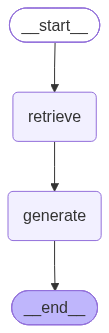

In [7]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

# now we will connect them using edges
graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)

graph = graph_builder.compile()

graph

In [8]:
test_query = "How will EVS impact oil demand in the next decade?"
result = graph.invoke({"query": test_query,"messages": []})

In [9]:
result

{'messages': [],
 'query': 'How will EVS impact oil demand in the next decade?',
 'retrieved_docs': [Document(metadata={'source': './documents/evs_oil_price_shock.pdf', 'total_pages': 15, 'title': '(anonymous)', 'trapped': '/False', 'creationdate': '2026-04-18T21:49:03+05:00', 'creator': '(unspecified)', 'page': 3, 'producer': 'ReportLab PDF Library - (opensource)', 'author': '(anonymous)', 'subject': '(unspecified)', 'moddate': '2026-04-18T21:49:03+05:00', 'page_label': '4', 'keywords': ''}, page_content='Energy Agency, and McKinsey collectively project that EVs will account for between 40 and\n60 percent of new vehicle sales globally by 2030. The stock of EVs on the road — which\nmatters more than annual sales for oil displacement — is projected to grow from roughly 40\nmillion vehicles today to between 300 and 500 million by the early 2030s. Whether this is\nsufficient to materially alter the oil price formation process is the central question this report\naddresses.\n1.1 Scope and 

In [10]:
print(result['generation'])

Short answer
- EVs will meaningfully reduce oil use in passenger and light-commercial vehicles over the next decade, but they will not eliminate oil demand — the displacement will be partial rather than complete.

Why (key facts from the report)
- By 2030 many forecasters expect EVs to make up roughly 40–60% of new vehicle sales.  
- The global EV stock is projected to grow from ~40 million today to about 300–500 million by the early 2030s.  
- The global passenger-vehicle fleet is roughly 1.4 billion vehicles (mostly ICE), so 300–500 million EVs would be ~21–36% of the fleet.  
- Oil displacement depends on three layers: new EV sales, retirement rates of the existing ICE fleet, and the mileage/fuel economy of the vehicles being displaced.  
- New vehicle sales are ~90 million/year and average vehicle lifetimes are long (15–20 years in developed markets, often longer in developing markets), so fleet turnover is slow.

Implications for the next decade
- The next decade should see substa